# Factor Investing - Brazil

The study below replicates factor investing strategies, which consist of selecting company stocks based on one or more characteristics. This type of strategy was first developed by Eugene Fama and Kenneth French during the 1990s, when they refined the CAPM formula by adding the Size (SMB) and Value (HML) factors. Below, a backtest is run to show the performance of these factors, alone and combined, in the Brazilian context.

In [1]:
# Library imports

import pandas as pd
import numpy as np
import statsmodels.api as sm
import quantstats as qs
from scipy import stats

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

from datetime import date, timedelta
from  bizdays import Calendar, set_option

cal = Calendar.load('ANBIMA')
set_option('mode', 'pandas')

### Settings from earlier versions

These are files imported and processed from the Comdinheiro API that were worked on in earlier versions of this notebook. Dates are converted to the datetime.date format.

In [2]:
# Imports data already collected to make the analysis easier

path = '.'
factors_folder = 'factors'
data_folder = 'data'

companies = pd.read_csv(path + "/" + data_folder + "/" + 'index_composition.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
prices_df = pd.read_csv(path + "/" + data_folder + "/" + 'prices.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volume = pd.read_csv(path + "/" + data_folder + "/" + 'volume.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
benchmarks = pd.read_csv(path + "/" + data_folder + "/" + 'benchmarks.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ff_factors = pd.read_csv(path + "/" + data_folder + "/" + 'ff_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Market factors
market_value = pd.read_csv(path + "/" + data_folder + "/" + 'relative_market_value.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
momentum = pd.read_csv(path + "/" + factors_folder + "/" + 'momentum.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
reversal = pd.read_csv(path + "/" + factors_folder + "/" + 'reversal.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volatility = pd.read_csv(path + "/" + factors_folder + "/" + 'volatility.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
bab = pd.read_csv(path + "/" + factors_folder + "/" + 'bab.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ivol = pd.read_csv(path + "/" + factors_folder + "/" + 'ivol.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Profitability factors
roe = pd.read_csv(path + "/" + factors_folder + "/" + 'roe.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
roa = pd.read_csv(path + "/" + factors_folder + "/" + 'roa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
gpoa = pd.read_csv(path + "/" + factors_folder + "/" + 'gpoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
cfoa = pd.read_csv(path + "/" + factors_folder + "/" + 'cfoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
acc = pd.read_csv(path + "/" + factors_folder + "/" + 'acc.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Growth factors
g_revenue = pd.read_csv(path + "/" + factors_folder + "/" + 'g_revenue.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
g_ebitda = pd.read_csv(path + "/" + factors_folder + "/" + 'g_ebitda.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
g_earnings = pd.read_csv(path + "/" + factors_folder + "/" + 'g_earnings.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
investments = pd.read_csv(path + "/" + factors_folder + "/" + 'investments.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Leverage factors
debt_to_assets = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_assets.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_to_ebitda = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_ebitda.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_to_equity = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_equity.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
liab_to_equity = pd.read_csv(path + "/" + factors_folder + "/" + 'liab_to_equity.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Value factors
earnings_yield = pd.read_csv(path + "/" + factors_folder + "/" + 'earnings_yield.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
book_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'book_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
sales_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'sales_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
fcf_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'fcf_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ebitda_ev = pd.read_csv(path + "/" + factors_folder + "/" + 'ebitda_ev.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Magic Formula
roc_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'roc_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
earnings_yield_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'earnings_yield_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_ebit_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_ebit_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Index rebalancing dates
rebalance_dates = sorted(companies.index.unique())

# Backtest dates
ini_date = cal.preceding(rebalance_dates[0] - timedelta(days = 1)).date()
end_date = date.today()

In [3]:
ticker_codes = [tick[0:4] for tick in sorted(companies['Ticker'].unique())]
repeated_tickers = [tick for tick in ticker_codes if ticker_codes.count(tick) > 1]
repeated_tickers = list(dict.fromkeys(repeated_tickers))

vol_median = volume.ffill(limit=1).rolling(42).median()

for tick in repeated_tickers:
    rep = volume.columns[volume.columns.str.contains(tick)]
    ticker_filter = vol_median[rep].apply(lambda r: np.where(r == r.max(), r, np.nan), axis = 1)
    vol_median[rep] = pd.DataFrame(ticker_filter.tolist(), columns = rep, index = vol_median.index)

# Building the signals and backtesting the strategies

Next we build the signals of each factor, individually and grouped. The first step is to define the assets eligible for investment according to these criteria: presence in the selected index or indices, and whether the stock had a price on that date. By default we use the stocks in the MLCX (Mid-Large Caps) and SMLL (Small Caps) indices, both created in 2009.
- The 'investable' dataframe shows which companies can be considered on every day of the sample: 1 means it is part of the sample and 0 that it is excluded from that period.

In [4]:
# Creates a matrix with the investable companies on each rebalancing date, showing the new index composition
investable = companies.loc[companies['Index'].isin(['SMLL', 'MLCX'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
investable = investable.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
investable = investable.reindex(market_value.index, method='ffill')
investable.loc[:date(2009,1,2)] = investable.loc[date(2009,1,5):date(2009,1,5)].values

# Creates a dataframe showing whether the stock had a price on the day, avoiding companies that left the market
has_price = prices_df.apply(lambda col: np.where((col.isna()) | (col <= 0), np.nan, 1)).loc[investable.index]

# Creates a dataframe to filter companies with low liquidity, avoiding companies whose prices are a problem to trade
volume_filter = vol_median.apply(lambda col: np.where(col > 1000, 1, np.nan))

In [5]:
# Sector filter for the Magic Formula
# Excludes Financials and Utilities companies
mf_filter = companies.loc[~companies['Sector'].isin(['Financeiro', 'Financeiro e Outros', 'Utilidade Pública'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
mf_filter = mf_filter.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
mf_filter = mf_filter.reindex(market_value.index, method='ffill')
mf_filter.loc[:date(2009,1,2)] = mf_filter.loc[date(2009,1,5):date(2009,1,5)].values

In [6]:
# Multiplies the indicators dataframe by investable and has_price to filter all dates at once
# Values multiplied by NaN become NaN, leaving only the values of companies that are investable on the date and have a price
roe = roe * investable * has_price * volume_filter
roa = roa * investable * has_price * volume_filter
gpoa = gpoa * investable * has_price * volume_filter
cfoa = cfoa * investable * has_price * volume_filter
acc = acc * investable * has_price * volume_filter

g_revenue = g_revenue * investable * has_price * volume_filter
g_ebitda = g_ebitda * investable * has_price * volume_filter
g_earnings = g_earnings * investable * has_price * volume_filter
investments = investments * investable * has_price * volume_filter

debt_to_assets = debt_to_assets * investable * has_price * volume_filter
debt_to_ebitda = debt_to_ebitda * investable * has_price * volume_filter
debt_to_equity = debt_to_equity * investable * has_price * volume_filter
liab_to_equity = liab_to_equity * investable * has_price * volume_filter

earnings_yield = earnings_yield * investable * has_price * volume_filter
book_to_price = book_to_price * investable * has_price * volume_filter
sales_to_price = sales_to_price * investable * has_price * volume_filter
fcf_to_price = fcf_to_price * investable * has_price * volume_filter
ebitda_ev = ebitda_ev * investable * has_price * volume_filter

momentum = momentum * investable * has_price * volume_filter
reversal = reversal * investable * has_price * volume_filter
volatility = volatility * investable * has_price * volume_filter
market_value = market_value * investable * has_price * volume_filter
bab = bab * investable * has_price * volume_filter
ivol = ivol * investable * has_price * volume_filter

roc_mf = roc_mf * investable * has_price * volume_filter * mf_filter
earnings_yield_mf = earnings_yield_mf * investable * has_price * volume_filter * mf_filter
debt_ebit_mf = debt_ebit_mf * investable * has_price * volume_filter * mf_filter

# Reindexes the dataframes so that all backtest dates are present
roe = roe.loc[volume.index]
roa = roa.loc[volume.index]
gpoa = gpoa.loc[volume.index]
cfoa = cfoa.loc[volume.index]
acc = acc.loc[volume.index]

g_revenue = g_revenue.loc[volume.index]
g_ebitda = g_ebitda.loc[volume.index]
g_earnings = g_earnings.loc[volume.index]
investments = investments.loc[volume.index]

debt_to_assets = debt_to_assets.loc[volume.index]
debt_to_ebitda = debt_to_ebitda.loc[volume.index]
debt_to_equity = debt_to_equity.loc[volume.index]
liab_to_equity = liab_to_equity.loc[volume.index]

earnings_yield = earnings_yield.loc[volume.index]
book_to_price = book_to_price.loc[volume.index]
sales_to_price = sales_to_price.loc[volume.index]
fcf_to_price = fcf_to_price.loc[volume.index]
ebitda_ev = ebitda_ev.loc[volume.index]

momentum = momentum.loc[volume.index]
reversal = reversal.loc[volume.index]
volatility = volatility.loc[volume.index]
market_value = market_value.loc[volume.index]
bab = bab.loc[volume.index]
ivol = ivol.loc[volume.index]

roc_mf = roc_mf.loc[volume.index]
earnings_yield_mf = earnings_yield_mf.loc[volume.index]
debt_ebit_mf = debt_ebit_mf.loc[volume.index]

## Z-Score and signal construction

After filtering which companies are available for investment, we apply a z-score to the indicators to build the factor signals. To remove outliers, we discard the values with a z-score beyond 2 standard deviations.

In [7]:
# Calculates z-scores using numpy
z_roe = stats.zscore(roe.values, axis=1, nan_policy='omit')
z_roa = stats.zscore(roa.values, axis=1, nan_policy='omit')
z_gpoa = stats.zscore(gpoa.values, axis=1, nan_policy='omit')
z_cfoa = stats.zscore(cfoa.values, axis=1, nan_policy='omit')
z_acc = stats.zscore(acc.values, axis=1, nan_policy='omit')
z_g_revenue = stats.zscore(g_revenue.values, axis=1, nan_policy='omit')
z_g_ebitda = stats.zscore(g_ebitda.values, axis=1, nan_policy='omit')
z_g_earnings = stats.zscore(g_earnings.values, axis=1, nan_policy='omit')
z_investments = stats.zscore(investments.values, axis=1, nan_policy='omit')
z_debt_to_assets = stats.zscore(debt_to_assets.values, axis=1, nan_policy='omit')
z_debt_to_ebitda = stats.zscore(debt_to_ebitda.values, axis=1, nan_policy='omit')
z_debt_to_equity = stats.zscore(debt_to_equity.values, axis=1, nan_policy='omit')
z_liab_to_equity = stats.zscore(liab_to_equity.values, axis=1, nan_policy='omit')
z_ey = stats.zscore(earnings_yield.values, axis=1, nan_policy='omit')
z_bp = stats.zscore(book_to_price.values, axis=1, nan_policy='omit')
z_sales = stats.zscore(sales_to_price.values, axis=1, nan_policy='omit')
z_fcf = stats.zscore(fcf_to_price.values, axis=1, nan_policy='omit')
z_ev = stats.zscore(ebitda_ev.values, axis=1, nan_policy='omit')
z_mom = stats.zscore(momentum.values, axis=1, nan_policy='omit')
z_rev = stats.zscore(reversal.values, axis=1, nan_policy='omit')
z_vol = stats.zscore(volatility.values, axis=1, nan_policy='omit')
z_size = stats.zscore(market_value.values, axis=1, nan_policy='omit')
z_bab = stats.zscore(bab.values, axis=1, nan_policy='omit')
z_ivol = stats.zscore(ivol.values, axis=1, nan_policy='omit')
z_roc_mf = stats.zscore(roc_mf.values, axis=1, nan_policy='omit')
z_ey_mf = stats.zscore(earnings_yield_mf.values, axis=1, nan_policy='omit')
z_de_mf = stats.zscore(debt_ebit_mf.values, axis=1, nan_policy='omit')

# Replaces values outside the [-2, 2] range with NaN
z_roe = np.where((z_roe >= -2) & (z_roe <= 2), z_roe, np.nan)
z_roa = np.where((z_roa >= -2) & (z_roa <= 2), z_roa, np.nan)
z_gpoa = np.where((z_gpoa >= -2) & (z_gpoa <= 2), z_gpoa, np.nan)
z_cfoa = np.where((z_cfoa >= -2) & (z_cfoa <= 2), z_cfoa, np.nan)
z_acc = np.where((z_acc >= -2) & (z_acc <= 2), z_acc, np.nan)
z_g_revenue = np.where((z_g_revenue >= -2) & (z_g_revenue <= 2), z_g_revenue, np.nan)
z_g_ebitda = np.where((z_g_ebitda >= -2) & (z_g_ebitda <= 2), z_g_ebitda, np.nan)
z_g_earnings = np.where((z_g_earnings >= -2) & (z_g_earnings <= 2), z_g_earnings, np.nan)
z_investments = np.where((z_investments >= -2) & (z_investments <= 2), z_investments, np.nan)
z_debt_to_assets = np.where((z_debt_to_assets >= -2) & (z_debt_to_assets <= 2), z_debt_to_assets, np.nan)
z_debt_to_ebitda = np.where((z_debt_to_ebitda >= -2) & (z_debt_to_ebitda <= 2), z_debt_to_ebitda, np.nan)
z_debt_to_equity = np.where((z_debt_to_equity >= -2) & (z_debt_to_equity <= 2), z_debt_to_equity, np.nan)
z_liab_to_equity = np.where((z_liab_to_equity >= -2) & (z_liab_to_equity <= 2), z_liab_to_equity, np.nan)
z_ey = np.where((z_ey >= -2) & (z_ey <= 2), z_ey, np.nan)
z_bp = np.where((z_bp >= -2) & (z_bp <= 2), z_bp, np.nan)
z_sales = np.where((z_sales >= -2) & (z_sales <= 2), z_sales, np.nan)
z_fcf = np.where((z_fcf >= -2) & (z_fcf <= 2), z_fcf, np.nan)
z_ev = np.where((z_ev >= -2) & (z_ev <= 2), z_ev, np.nan)
z_roc_mf = np.where((z_roc_mf >= -2) & (z_roc_mf <= 2), z_roc_mf, np.nan)
z_ey_mf = np.where((z_ey_mf >= -2) & (z_ey_mf <= 2), z_ey_mf, np.nan)
z_de_mf = np.where((z_de_mf >= -2) & (z_de_mf <= 2), z_de_mf, np.nan)

# Converts the result back to a DataFrame, preserving index and columns
z_roe = pd.DataFrame(z_roe, columns=roe.columns, index=roe.index)
z_roa = pd.DataFrame(z_roa, columns=roa.columns, index=roa.index)
z_gpoa = pd.DataFrame(z_gpoa, columns=gpoa.columns, index=gpoa.index)
z_cfoa = pd.DataFrame(z_cfoa, columns=cfoa.columns, index=cfoa.index)
z_acc = pd.DataFrame(z_acc, columns=acc.columns, index=acc.index)
z_g_revenue = pd.DataFrame(z_g_revenue, columns=g_revenue.columns, index=g_revenue.index)
z_g_ebitda = pd.DataFrame(z_g_ebitda, columns=g_ebitda.columns, index=g_ebitda.index)
z_g_earnings = pd.DataFrame(z_g_earnings, columns=g_earnings.columns, index=g_earnings.index)
z_investments = pd.DataFrame(z_investments, columns=investments.columns, index=investments.index)
z_debt_to_assets = pd.DataFrame(z_debt_to_assets, columns=debt_to_assets.columns, index=debt_to_assets.index)
z_debt_to_ebitda = pd.DataFrame(z_debt_to_ebitda, columns=debt_to_ebitda.columns, index=debt_to_ebitda.index)
z_debt_to_equity = pd.DataFrame(z_debt_to_equity, columns=debt_to_equity.columns, index=debt_to_equity.index)
z_liab_to_equity = pd.DataFrame(z_liab_to_equity, columns=liab_to_equity.columns, index=liab_to_equity.index)
z_ey = pd.DataFrame(z_ey, columns=earnings_yield.columns, index=earnings_yield.index)
z_bp = pd.DataFrame(z_bp, columns=book_to_price.columns, index=book_to_price.index)
z_sales = pd.DataFrame(z_sales, columns=sales_to_price.columns, index=sales_to_price.index)
z_fcf = pd.DataFrame(z_fcf, columns=fcf_to_price.columns, index=fcf_to_price.index)
z_ev = pd.DataFrame(z_ev, columns=ebitda_ev.columns, index=ebitda_ev.index)
z_mom = pd.DataFrame(z_mom, columns=momentum.columns, index=momentum.index)
z_rev = pd.DataFrame(z_rev, columns=reversal.columns, index=reversal.index)
z_vol = pd.DataFrame(z_vol, columns=volatility.columns, index=volatility.index)
z_size = pd.DataFrame(z_size, columns=market_value.columns, index=market_value.index)
z_bab = pd.DataFrame(z_bab, columns=bab.columns, index=bab.index)
z_ivol = pd.DataFrame(z_ivol, columns=ivol.columns, index=ivol.index)
z_roc_mf = pd.DataFrame(z_roc_mf, columns=roc_mf.columns, index=roc_mf.index)
z_ey_mf = pd.DataFrame(z_ey_mf, columns=earnings_yield_mf.columns, index=earnings_yield_mf.index)
z_de_mf = pd.DataFrame(z_de_mf, columns=debt_ebit_mf.columns, index=debt_ebit_mf.index)

# Calculates the aggregate scores
z_profitability = z_roe + z_gpoa + z_cfoa + z_acc + z_roa
z_growth = z_g_revenue + z_g_ebitda + z_g_earnings
z_safety = -z_debt_to_assets - z_debt_to_ebitda - z_liab_to_equity
z_value = z_ev + z_ey + z_fcf + z_bp + z_sales
z_mf = -stats.zscore(roc_mf.rank(axis=1, ascending=False) + earnings_yield_mf.rank(axis=1, ascending=False) + debt_ebit_mf.rank(axis=1, ascending=True), axis=1, nan_policy='omit')

# Converts the final result to a DataFrame
z_mf = pd.DataFrame(z_mf, columns=roc_mf.columns, index=roc_mf.index)

## Portfolio backtest

All stocks are rebalanced on the first business day of each month, with equal weights.

In [8]:
from brfactors.selection import get_quintiles, get_longshort_decile, get_longshort_amount
from brfactors.backtest import backtest_quintiles, backtest_longshort

# Comparing the factors

Next we compare the performance of all factors against each other, dividing them into the components Profitability, Value, Momentum, Volatility, Growth and Leverage.
<br>We need to know which factors have a real premium, whether the premium beats the benchmark, and whether combining factors can improve the overall performance of the portfolio.

In [9]:
# Value Factors
value = {'Book to Price' : z_bp, 'EV to Ebitda' : z_ev, 'Sales to Price' : z_sales, 'Free Cash Flow to Price' : z_fcf, 'Earnings Yield' : z_ey, 'Value Composite' : z_value}
profitability = {'Return on Equity' : z_roe, 'Return on Assets' : z_roa, 'Gross Profit over Assets' : z_gpoa, 'Cashflow over Assets' : z_cfoa, 'Accruals' : z_acc, 'Profitability Composite' : z_profitability}
growth = {'Revenue Growth' : z_g_revenue, 'Ebitda Growth' : z_g_ebitda, 'Earnings Growth' : z_g_earnings, 'Growth Composite' : z_growth, "Investments": z_investments}
leverage = {'Debt to Assets' : -z_debt_to_assets, 'Debt to Ebitda' : -z_debt_to_ebitda, 'Debt to Equity' : -z_debt_to_equity, 'Liabilities to Equity' : -z_liab_to_equity, 'Leverage Composite' : z_safety}
market = {'Momentum' : z_mom, 'Reversal' : z_rev, 'Low Vol' : -z_vol, 'Size' : -z_size, 'BAB' : z_bab, 'IVOL' : -z_ivol}
magic_formula = {'Return on Capital' : z_roc_mf, 'Earnings Yield MF' : z_ey_mf, 'Debt to Ebit MF' : -z_de_mf, 'Magic Formula Composite' : z_mf}

# List with all factors
factors_dict = dict()
factors_dict.update(value)
factors_dict.update(profitability)
factors_dict.update(growth)
factors_dict.update(leverage)
factors_dict.update(market)
factors_dict.update(magic_formula)

In [10]:
# Creates a list with all rebalancing dates
rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1,13, 1)]

# Checks whether the date is a business day, if not, returns the next business day
rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date < date.today()]

## Quintile performance

In this section we assess the performance of each quintile over the period, seeking to identify a premium in the factors. To do so we compare the annualized mean return of each portfolio.
<br>The expected behavior is a gradual improvement in the mean return from the first to the fifth portfolio.

In [11]:
factors_quintiles_returns = dict()
for factor_name, factor_data in factors_dict.items():

    # Creates a dictionary with the 5 quintiles and their companies
    quintiles = {'{:.0f}Q'.format((n+2)/2): get_quintiles(n/10, (n+2)/10, factor_data) for n in range(0,10, 2)}

    # Calculates the daily return for all quintiles
    quintiles_returns = {k: backtest_quintiles(prices_df, v, rebalance_dates, market_value) for k,v in zip(quintiles.keys(), quintiles.values())}
    
    factors_quintiles_returns[factor_name] = pd.DataFrame(quintiles_returns)

factors_quintiles_returns_df = pd.DataFrame({k: v.mean() * (252) for k,v in zip(factors_quintiles_returns.keys(), factors_quintiles_returns.values())}).T
factors_quintiles_returns_df['5Q - 1Q'] = factors_quintiles_returns_df['5Q'] - factors_quintiles_returns_df['1Q']
factors_quintiles_returns_df['p-value'] = [stats.ttest_ind(factors_quintiles_returns[fac]['5Q'] - benchmarks['CDI'], factors_quintiles_returns[fac]['1Q'] - benchmarks['CDI'], nan_policy = 'omit')[1] for fac in factors_quintiles_returns_df.index]
factors_quintiles_returns_df.sort_values(by = '5Q - 1Q', ascending = False).map('{:,.2%}'.format)

,1Q,2Q,3Q,4Q,5Q,5Q - 1Q,p-value
Momentum,1.05%,9.61%,14.20%,16.57%,17.73%,16.69%,6.67%
Return on Capital,0.86%,9.98%,15.80%,12.84%,14.77%,13.91%,13.91%
IVOL,0.71%,6.97%,8.40%,12.80%,11.61%,10.90%,19.33%
Return on Equity,4.17%,14.51%,13.36%,14.85%,14.80%,10.63%,21.41%
Earnings Yield MF,9.48%,12.40%,11.31%,12.48%,18.44%,8.97%,29.70%
BAB,3.71%,8.83%,10.15%,8.66%,12.55%,8.84%,31.96%
Low Vol,6.98%,10.97%,11.54%,14.64%,14.92%,7.95%,37.12%
Cashflow over Assets,2.42%,10.98%,8.92%,12.44%,10.36%,7.94%,31.08%
Return on Assets,6.15%,14.38%,13.13%,14.19%,13.50%,7.35%,38.11%
Debt to Ebit MF,9.21%,12.58%,11.48%,16.18%,16.20%,6.99%,42.47%


## Cumulative performance, Long and Short separately

In this section we assess the performance of the portfolios while increasing the size of the percentile used, seeking to identify a gradual increase between portfolios concentrated on the short side and those concentrated on the long side. To do so we compare the annualized mean return of each portfolio.
<br>The expected behavior is a gradual improvement in the mean return from the first to the fifth portfolio.

In [12]:
factors_percentiles_returns = dict()
for factor_name, factor_data in factors_dict.items():

    # Creates a dictionary with the 5 quintiles and their companies
    percentiles = {'{:.0%}'.format(n/10): get_longshort_decile(n/10, factor_data) for n in [1,2,3,4,5]}

    # Calculates the daily return for all quintiles
    short_returns = {k: backtest_quintiles(prices_df, v[0], rebalance_dates, market_value) for k,v in zip(percentiles.keys(), percentiles.values())}
    long_returns = {k: backtest_quintiles(prices_df, v[1], rebalance_dates, market_value) for k,v in zip(percentiles.keys(), percentiles.values())}

    percentiles_returns_df = pd.concat([pd.DataFrame(short_returns), pd.DataFrame(long_returns).get(list(long_returns.keys())[::-1])], axis = 1)

    percentiles_returns_df.columns = ['-10%', '-20%', '-30%', '-40%', '-50%', '+50%', '+40%', '+30%', '+20%', '+10%']

    factors_percentiles_returns[factor_name] = percentiles_returns_df

factors_percentiles_returns_df = pd.DataFrame({k: v.mean() * (252) for k,v in zip(factors_percentiles_returns.keys(), factors_percentiles_returns.values())}).T
factors_percentiles_returns_df.map('{:,.2%}'.format)

,-10%,-20%,-30%,-40%,-50%,+50%,+40%,+30%,+20%,+10%
Book to Price,13.18%,12.33%,11.54%,11.47%,11.27%,13.80%,13.75%,13.54%,14.40%,13.88%
EV to Ebitda,3.50%,6.36%,7.54%,8.02%,7.47%,11.70%,12.01%,10.83%,12.08%,13.21%
Sales to Price,8.90%,11.10%,11.20%,11.28%,11.35%,12.28%,11.70%,10.46%,11.30%,11.26%
Free Cash Flow to Price,9.34%,10.18%,9.79%,9.71%,9.71%,10.91%,11.83%,11.83%,12.53%,14.74%
Earnings Yield,8.31%,11.67%,12.41%,12.23%,12.22%,14.77%,14.64%,15.99%,13.93%,12.28%
Value Composite,10.64%,10.28%,8.82%,10.13%,9.58%,11.75%,11.60%,11.88%,11.18%,12.63%
Return on Equity,-0.64%,4.17%,7.87%,9.35%,9.84%,14.92%,14.83%,15.02%,14.68%,13.50%
Return on Assets,1.21%,6.15%,8.25%,10.25%,11.12%,13.37%,13.91%,13.63%,13.26%,13.64%
Gross Profit over Assets,2.27%,7.29%,9.69%,10.72%,11.17%,12.01%,12.77%,11.22%,13.67%,16.90%
Cashflow over Assets,0.31%,2.42%,4.18%,6.55%,6.98%,11.15%,11.41%,11.44%,10.17%,9.74%


In [13]:
factors_ls_returns = dict()
for factor_name, factor_data in factors_dict.items():

    # Creates a dictionary with the 5 quintiles and their companies
    percentiles = {'{:.0%}'.format(n/10): get_longshort_decile(n/10, factor_data) for n in [1,2,3,4,5]}

    # Calculates the daily return for all quintiles
    factor_returns = {k: backtest_longshort(prices_df, v[0], v[1], rebalance_dates, market_value) for k,v in zip(percentiles.keys(), percentiles.values())}

    factors_ls_returns[factor_name] = pd.DataFrame(factor_returns)

factors_ls_returns_df = pd.DataFrame({k: v.mean() * (252) for k,v in zip(factors_ls_returns.keys(), factors_ls_returns.values())}).T
factors_ls_returns_df.map('{:,.2%}'.format)

,10%,20%,30%,40%,50%
Book to Price,1.22%,2.21%,2.27%,2.42%,2.72%
EV to Ebitda,9.43%,5.44%,3.00%,3.89%,4.21%
Sales to Price,2.96%,0.69%,-0.25%,0.84%,1.27%
Free Cash Flow to Price,5.67%,2.36%,2.09%,2.12%,1.11%
Earnings Yield,3.41%,1.79%,3.38%,2.39%,2.42%
Value Composite,2.10%,1.05%,3.13%,1.54%,2.15%
Return on Equity,12.74%,9.45%,6.48%,4.84%,4.60%
Return on Assets,10.79%,5.61%,4.25%,2.69%,1.54%
Gross Profit over Assets,14.84%,6.29%,1.48%,1.98%,0.89%
Cashflow over Assets,7.95%,6.72%,6.67%,4.36%,3.68%


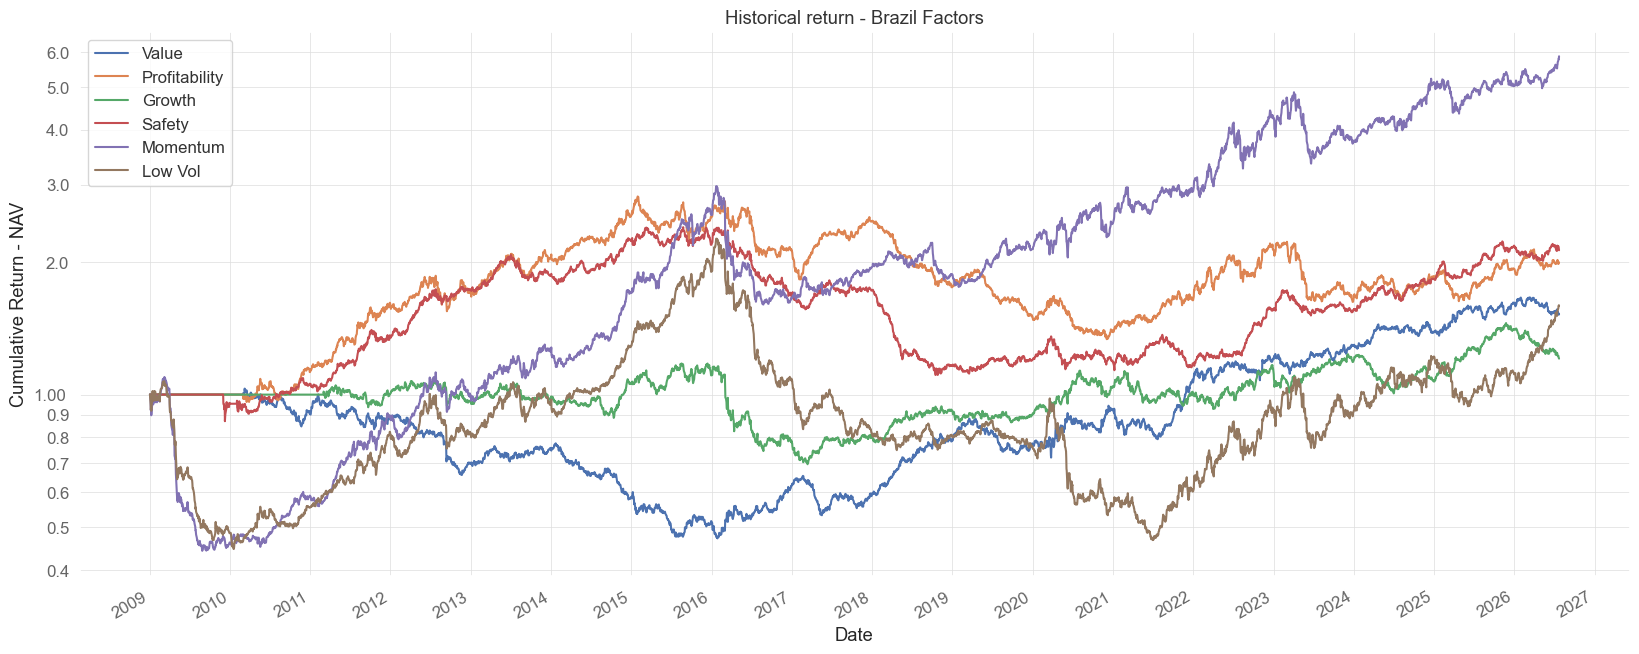

In [14]:
factors_ls_returns['Value Composite']['30%'].add(1).cumprod().plot(figsize = (20,8), title = 'Historical return - Brazil Factors', label = 'Value')
factors_ls_returns['Profitability Composite']['30%'].add(1).cumprod().plot(figsize = (20,8), title = 'Historical return - Brazil Factors', label = 'Profitability')
factors_ls_returns['Growth Composite']['30%'].add(1).cumprod().plot(figsize = (20,8), title = 'Historical return - Brazil Factors', label = 'Growth')
factors_ls_returns['Leverage Composite']['30%'].add(1).cumprod().plot(figsize = (20,8), title = 'Historical return - Brazil Factors', label = 'Safety')
factors_ls_returns['Momentum']['30%'].add(1).cumprod().plot(figsize = (20,8), title = 'Historical return - Brazil Factors', label = 'Momentum')
factors_ls_returns['Low Vol']['30%'].add(1).cumprod().plot(figsize = (20,8), title = 'Historical return - Brazil Factors', label = 'Low Vol')

plt.legend()
plt.yscale('log')
plt.ylabel('Cumulative Return - NAV')
plt.xlabel('Date')

# Adjusts the number of ticks on the Y axis
plt.gca().yaxis.set_major_locator(ticker.LogLocator(base=10.0))  # Major ticks
plt.gca().yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs = 'auto'))  # Minor ticks

# Formats the Y axis values for better readability
plt.gca().yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.gca().yaxis.set_minor_formatter(ticker.ScalarFormatter())

# Sets the X axis spacing to 1 year
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))  # Major ticks every 1 year
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Formats the dates to show only the year

# Adds grid lines for the major and minor ticks
plt.grid(True, which='both')

<Axes: >

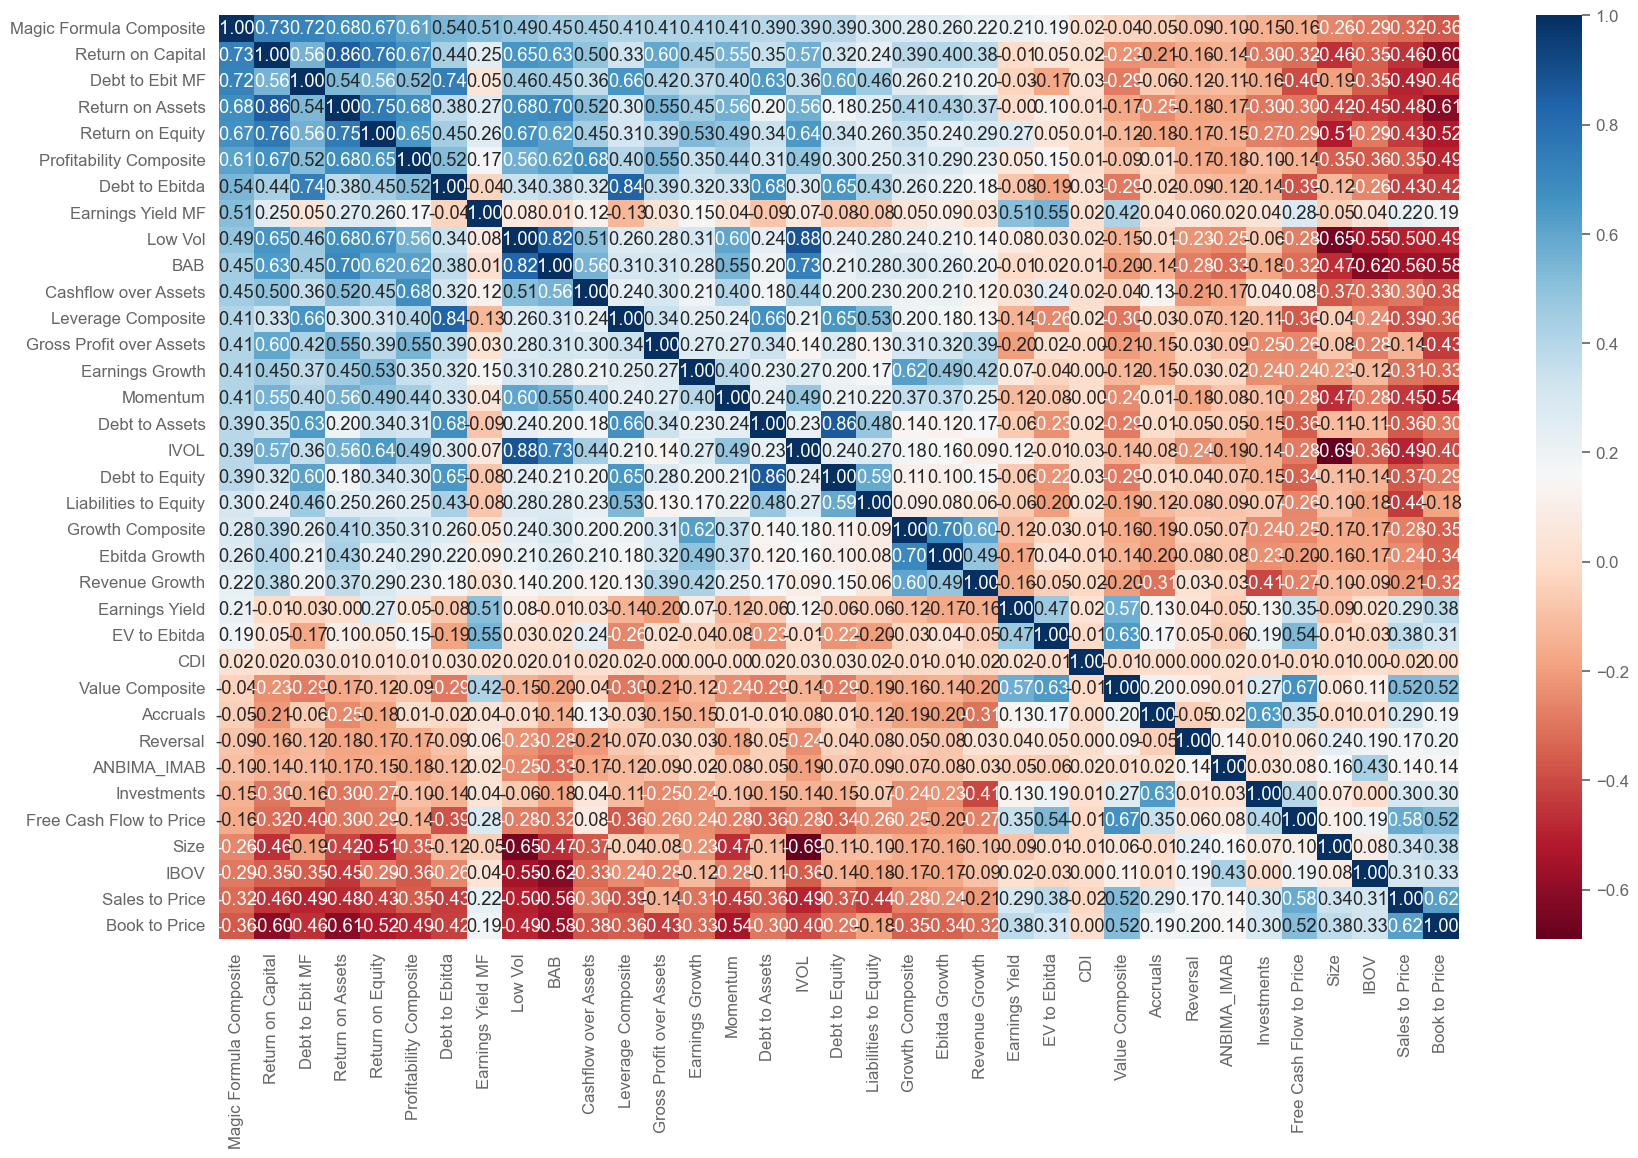

In [15]:
import seaborn as sns

facs = pd.concat([factors_ls_returns[fac]['30%'] for fac in factors_ls_returns.keys()], axis = 1).dropna(how = 'all')
facs.columns = factors_ls_returns.keys()
facs = facs.merge(benchmarks[['IBOV', 'CDI', 'ANBIMA_IMAB']], how = 'left', left_index=True, right_index=True)

xx = facs.corr()
ii = xx['Magic Formula Composite'].sort_values(ascending = False).index

plt.figure(figsize = (20,12))
sns.heatmap(xx.loc[ii,ii], cmap = 'RdBu', annot= True, fmt=".2f")

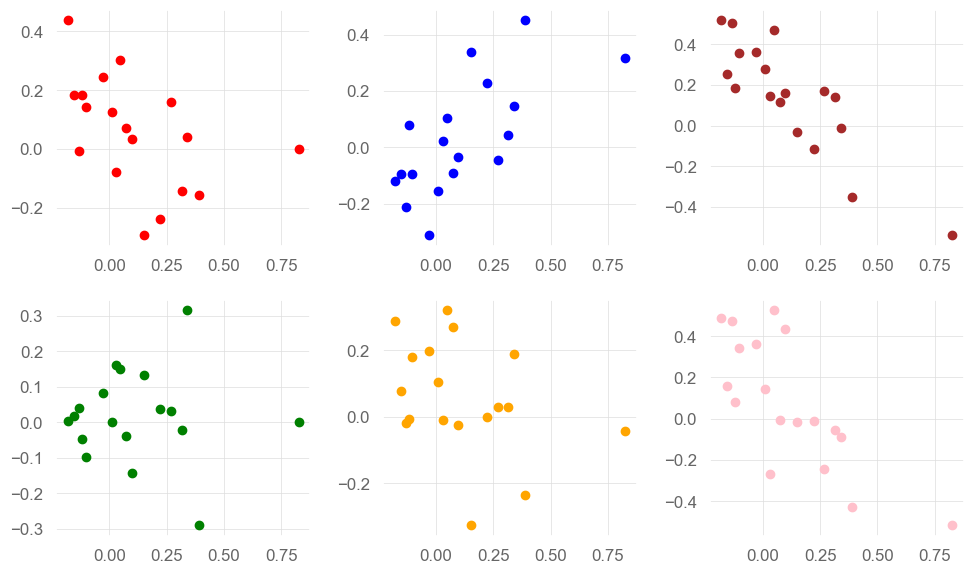

In [16]:
facs_annual = facs.resample('YE').agg(lambda t: t.add(1).prod() - 1)
fig, ax = plt.subplots(nrows = 2, ncols = 3)
fig.tight_layout()

ax[0,0].scatter(facs_annual['IBOV'], facs_annual['Profitability Composite'], c = 'red')
ax[0,1].scatter(facs_annual['IBOV'], facs_annual['Book to Price'], c = 'blue')
ax[0,2].scatter(facs_annual['IBOV'], facs_annual['Momentum'], c = 'brown')
ax[1,0].scatter(facs_annual['IBOV'], facs_annual['Growth Composite'], c = 'green')
ax[1,1].scatter(facs_annual['IBOV'], facs_annual['Leverage Composite'], c = 'orange')
ax[1,2].scatter(facs_annual['IBOV'], facs_annual['Low Vol'], c = 'pink')

# facs_annual.corr().get('IBOV').sort_values(ascending = False)
# ii = xx['IBOV'].sort_values().index

# plt.figure(figsize = (20,12))
# sns.heatmap(xx.loc[ii,ii], cmap = 'RdBu', annot= True, fmt=".2f")

In [17]:
# Factor trend following
# Cumulative return of the strategy
# factors_quintiles_returns_df = pd.DataFrame({k: v['Daily return'] for k,v in zip(factors_ls_returns.keys(), factors_ls_returns.values())}).replace(0, np.nan)
ret_strategy = prices_df

# Exponential moving average (EWMA)
ewm_mean_5d = ret_strategy.ewm(span = 10).mean()
ewm_mean_21d = ret_strategy.ewm(span = 21).mean()
ewm_mean_63d = ret_strategy.ewm(span = 63).mean()
ewm_mean_126d = ret_strategy.ewm(span = 126).mean()
ewm_mean_252d = ret_strategy.ewm(span = 252).mean()

# Calculation of the spreads between the moving averages
spread_5d_21d = ewm_mean_5d - ewm_mean_21d
spread_21d_63d = ewm_mean_21d - ewm_mean_63d
spread_63d_126d = ewm_mean_63d - ewm_mean_126d
spread_126d_252d = ewm_mean_126d - ewm_mean_252d

# Normalization of the spreads by the standard deviation
norm_spread_5d_21d = spread_5d_21d / spread_5d_21d.rolling(252).std()
norm_spread_21d_63d = spread_21d_63d / spread_21d_63d.rolling(252).std()
norm_spread_63d_126d = spread_63d_126d / spread_63d_126d.rolling(252).std()
norm_spread_126d_252d = spread_126d_252d / spread_126d_252d.rolling(252).std()

# Trend signal calculation with the hyperbolic tangent
signal_5d_21d = np.tanh(norm_spread_5d_21d)
signal_21d_63d = np.tanh(norm_spread_21d_63d)
signal_63d_126d = np.tanh(norm_spread_63d_126d)
signal_126d_252d = np.tanh(norm_spread_126d_252d)

# Adjusted trend signal calculation: average of the signals
trend_signal = (signal_5d_21d + signal_21d_63d + signal_63d_126d + signal_126d_252d) / 4
trend_signal = trend_signal.mul(investable * has_price * volume_filter)

In [18]:
# # List of dates by weekday for weekly rebalancing
# def get_weekday_list(week_day, year, month):
#     # Creates a list of dates from the weekday given in the parameter, adding seven days up to a limit date
#     first_date = cal.getdate(week_day, year, month)
#     date_list = [first_date]

#     while (date_list[-1] + timedelta(7)).date() < date.today():
#         date_list.append(date_list[-1] + timedelta(7))

#     return date_list

# rebalance_dates = [cal.following(dt) for dt in get_weekday_list('first mon', 2009, 1)] # All Mondays that are business days from 2009 to May/2025

# rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1,13, 1)]
# rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date < date.today()]

rebalance_dates = prices_df.loc[date(2009,1,1):].index.tolist()

In [19]:
# Creates a dictionary with the 5 quintiles and their companies
quintiles = {'{:.0f}Q'.format((n+2)/2): get_quintiles(n/10, (n+2)/10, trend_signal) for n in range(0,10, 2)}
# Calculates the daily return for all quintiles
quintiles_returns = {k: backtest_quintiles(prices_df, v, rebalance_dates, market_value) for k,v in zip(quintiles.keys(), quintiles.values())}

bottom_20, top_20 = get_longshort_amount(20, trend_signal)
top_returns = backtest_quintiles(prices_df, top_20, rebalance_dates, market_value)

quintiles_returns.update({'Top 20': top_returns})

Annualized return - Trend Follow:
 1Q        0.045880
2Q        0.103249
3Q        0.130182
4Q        0.133265
5Q        0.186719
Top 20    0.200383
dtype: float64
Annualized volatility - Trend Follow:
 1Q        0.286796
2Q        0.266169
3Q        0.243014
4Q        0.224519
5Q        0.188239
Top 20    0.188684
dtype: float64


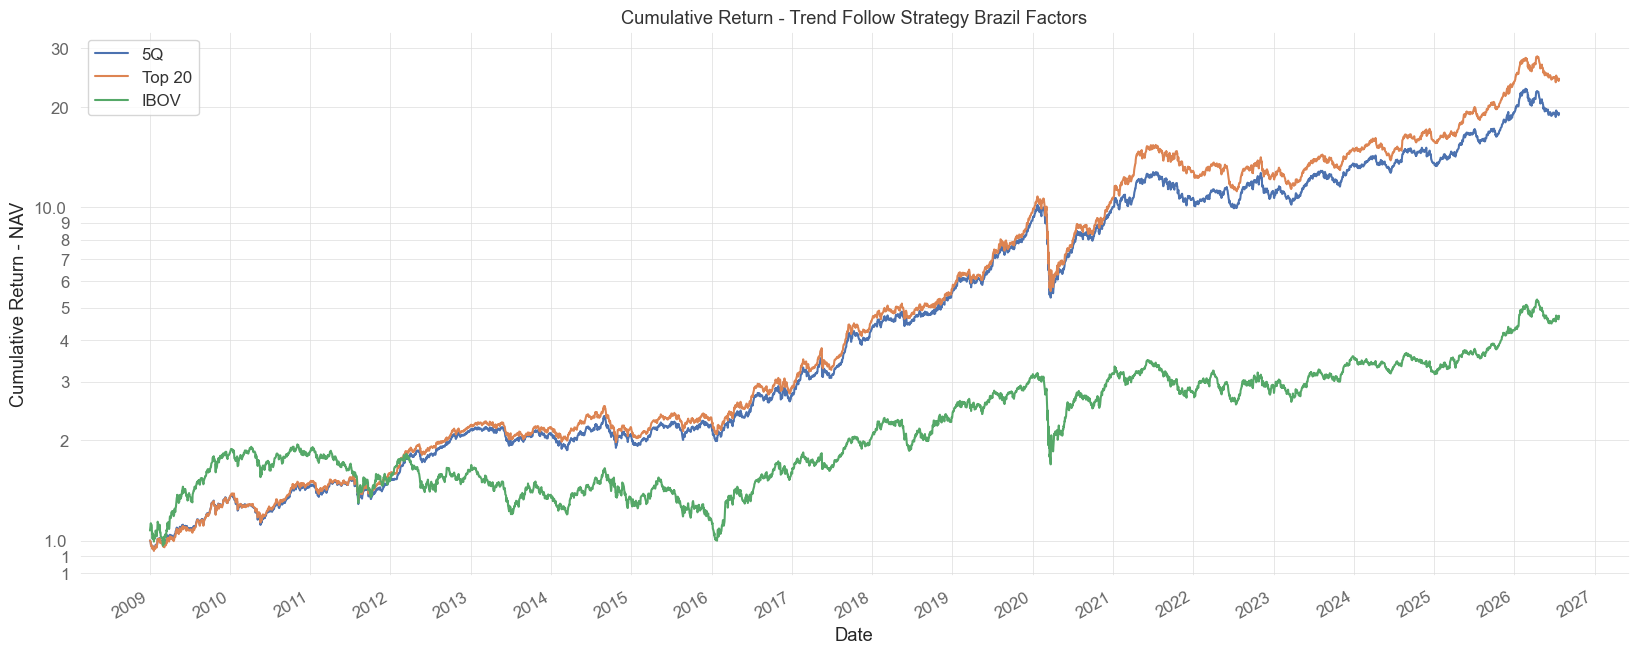

In [20]:
# sig_mean = trend_signal_adj.get(['Profitability Composite', 'Value Composite', 'Growth Composite', 'Momentum', 'Low Vol']).mean(axis = 1)
# sig_sum = trend_signal_adj.get(['Profitability Composite', 'Value Composite', 'Growth Composite', 'Momentum', 'Low Vol']).sum(axis = 1)
# sig_wgts = trend_signal_adj.get(['Profitability Composite', 'Value Composite', 'Growth Composite', 'Momentum', 'Low Vol']).div(sig_sum, axis = 0).fillna(1/5).mul(sig_mean, axis = 0)
# ret_test = factors_quintiles_returns_df.mul(sig_wgts.shift(0)).sum(axis = 1).loc[date(2012,1,1):]

quintiles_returns_df = pd.DataFrame(quintiles_returns).dropna(how = 'all')
quintiles_returns_df[['5Q', 'Top 20']].add(1).cumprod().plot(figsize = (20,8), title = 'Cumulative Return - Trend Follow Strategy Brazil Factors', label = 'Trend Follow')
benchmarks['IBOV'].loc[quintiles_returns_df.index].add(1).cumprod().plot(figsize = (20,8), title = 'Cumulative Return - Trend Follow Strategy Brazil Factors', label = 'IBOV')

plt.legend()
plt.yscale('log')
plt.ylabel('Cumulative Return - NAV')
plt.xlabel('Date')

# Adjusts the number of ticks on the Y axis
plt.gca().yaxis.set_major_locator(ticker.LogLocator(base=10.0))  # Major ticks
plt.gca().yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs = 'auto'))  # Minor ticks

# Formats the Y axis values for better readability
plt.gca().yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.gca().yaxis.set_minor_formatter(ticker.ScalarFormatter())

# Sets the X axis spacing to 1 year
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))  # Major ticks every 1 year
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Formats the dates to show only the year

# Adds grid lines for the major and minor ticks
plt.grid(True, which='both')

print('Annualized return - Trend Follow:\n', quintiles_returns_df.mean() * 252)
print('Annualized volatility - Trend Follow:\n', quintiles_returns_df.std() * np.sqrt(252))

<Axes: title={'center': 'Drawdown - Trend Follow Strategy Brazil Factors'}, xlabel='Date'>

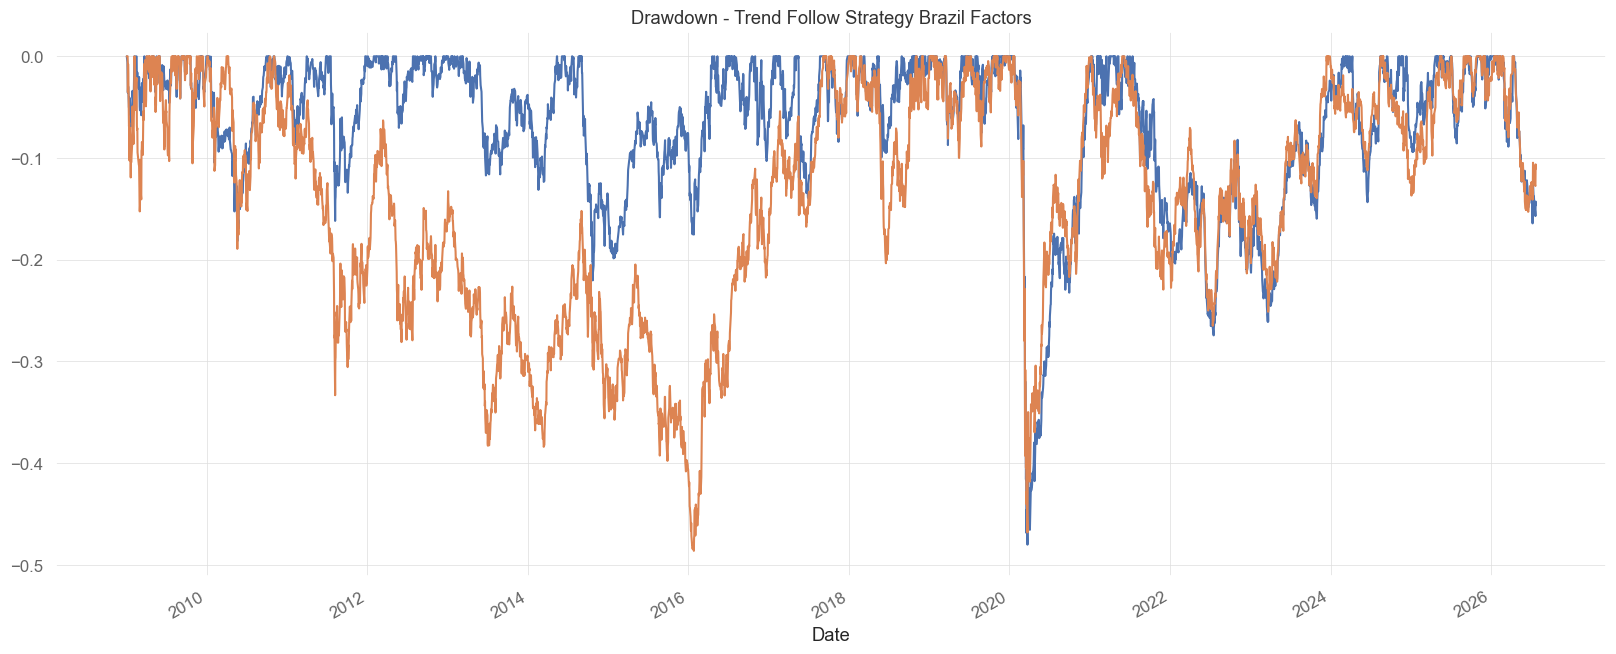

In [21]:
qs.stats.to_drawdown_series(quintiles_returns_df['Top 20']).plot(figsize = (20,8), title = 'Drawdown - Trend Follow Strategy Brazil Factors', label = 'Trend Follow')
qs.stats.to_drawdown_series(benchmarks['IBOV'].loc[quintiles_returns_df.index]).plot(figsize = (20,8), title = 'Drawdown - Trend Follow Strategy Brazil Factors', label = 'IBOV')

In [22]:
monthly_returns = quintiles_returns_df.resample('ME').agg(lambda t: t.add(1).prod() - 1)
monthly_returns = monthly_returns.pivot_table(index = monthly_returns.index.year, columns = monthly_returns.index.month, values = 'Top 20')
monthly_returns.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_returns['YTD'] = monthly_returns.apply(lambda x: (x.add(1).prod() - 1), axis = 1)
monthly_returns.fillna(0).map('{:,.2%}'.format)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,YTD
Date,,,,,,,,,,,,,
2009,-4.13%,3.51%,0.72%,5.46%,4.13%,-2.44%,4.69%,1.94%,5.91%,1.16%,4.94%,4.80%,34.65%
2010,-3.18%,-3.04%,1.59%,-3.45%,-3.37%,4.21%,6.46%,-0.89%,5.15%,6.02%,-0.11%,1.86%,10.98%
2011,-5.05%,0.98%,5.11%,0.04%,0.09%,2.17%,-2.74%,-2.87%,-3.50%,4.82%,3.79%,3.89%,6.23%
2012,1.56%,10.98%,4.27%,3.16%,-3.87%,3.02%,2.22%,1.91%,4.08%,2.84%,0.95%,3.16%,39.41%
2013,1.61%,0.58%,0.53%,-2.40%,-0.27%,-5.92%,0.17%,-1.50%,1.05%,6.22%,-1.13%,0.52%,-0.97%
2014,-5.40%,-1.42%,4.69%,2.18%,2.73%,4.60%,-0.36%,8.02%,-12.74%,-2.71%,3.18%,-1.44%,-0.36%
2015,-7.05%,4.58%,4.11%,3.78%,0.58%,2.45%,0.29%,-6.88%,3.64%,-1.09%,3.39%,0.01%,7.13%
2016,-5.35%,3.66%,3.56%,8.75%,-3.64%,8.59%,9.23%,-4.33%,-1.01%,9.98%,-2.49%,-4.07%,23.06%
2017,10.12%,7.25%,-3.49%,6.45%,-2.65%,-2.79%,7.06%,11.92%,7.28%,1.01%,-1.99%,8.30%,58.28%


In [23]:
monthly_returns = benchmarks.resample('ME').agg(lambda t: t.add(1).prod() - 1)
monthly_returns = monthly_returns.pivot_table(index = monthly_returns.index.year, columns = monthly_returns.index.month, values = 'IBOV')
monthly_returns.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_returns['YTD'] = monthly_returns.apply(lambda x: (x.add(1).prod() - 1), axis = 1)
monthly_returns.fillna(0).map('{:,.2%}'.format)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,YTD
Date,,,,,,,,,,,,,
2007,-1.63%,-1.68%,4.36%,6.88%,6.77%,4.06%,-0.39%,0.84%,10.67%,8.02%,-3.54%,1.40%,40.77%
2008,-6.88%,6.72%,-3.97%,11.32%,6.96%,-10.44%,-8.48%,-6.43%,-11.03%,-24.80%,-1.77%,2.61%,-41.22%
2009,4.66%,-2.84%,7.18%,15.55%,12.49%,-3.26%,6.41%,3.15%,8.90%,0.05%,8.93%,2.30%,82.66%
2010,-4.65%,1.68%,5.82%,-4.04%,-6.64%,-3.35%,10.80%,-3.51%,6.58%,1.79%,-4.20%,2.36%,1.04%
2011,-3.94%,1.22%,1.79%,-3.58%,-2.29%,-3.43%,-5.74%,-3.96%,-7.38%,11.49%,-2.51%,-0.21%,-18.11%
2012,11.13%,4.34%,-1.98%,-4.17%,-11.86%,-0.25%,3.21%,1.72%,3.70%,-3.56%,0.71%,6.05%,7.40%
2013,-1.95%,-3.91%,-1.87%,-0.78%,-4.30%,-11.31%,1.64%,3.68%,4.65%,3.66%,-3.27%,-1.86%,-15.50%
2014,-7.51%,-1.14%,7.05%,2.40%,-0.75%,3.76%,5.00%,9.78%,-11.70%,0.95%,0.07%,-8.52%,-2.91%
2015,-6.20%,9.97%,-0.84%,9.93%,-6.17%,0.61%,-4.17%,-8.33%,-3.36%,1.80%,-1.63%,-3.93%,-13.31%


In [24]:
# Factor exposure of the portfolio
returns_ff = pd.merge(quintiles_returns_df['Top 20'], ff_factors[["Mkt_RF", "SMB", "HML", "RMW", "CMA", "Risk_Free"]], how = 'left', left_index = True, right_index = True).dropna()
returns_ff['Excess_Return'] = returns_ff['Top 20'] - returns_ff['Risk_Free']
monthly_returns = returns_ff.resample('ME').apply(lambda x: (x + 1).prod() - 1)

Y = monthly_returns['Excess_Return']
X = monthly_returns[['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA']]
X = sm.add_constant(X)  # Adds a constant for the intercept
model = sm.OLS(Y, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Excess_Return   R-squared:                       0.651
Model:                            OLS   Adj. R-squared:                  0.642
Method:                 Least Squares   F-statistic:                     76.31
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           6.69e-45
Time:                        01:10:50   Log-Likelihood:                 421.76
No. Observations:                 211   AIC:                            -831.5
Df Residuals:                     205   BIC:                            -811.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0085      0.002      3.699      0.000       0.004       0.013
Mkt_RF         0.7737      0.046     16.865      0.000       0.683       0.864
SMB            0.2678      0.059      4.574      0.000       0.152       0.383
HML           -0.3728      0.075     -4.978      0.000      -0.520      -0.225
RMW            0.0909      0.074      1.230      0.220      -0.055       0.237
CMA            0.2244      0.074      3.020      0.003       0.078       0.371
==============================================================================
Omnibus:                        8.592   Durbin-Watson:                   1.952
Prob(Omnibus):                  0.014   Jarque-Bera (JB):               14.056
Skew:                           0.182   Prob(JB):                     0.000887
Kurtosis:                       4.211   Cond. No.                         41.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""